# 23_K-Means Clustering

# K-Means Clustering

## Learning Objectives

- Classification과 Clustering의 차이를 설명할 수 있다.
- K-Means의 `Assignment → Update → Repeat` 과정을 이해한다.
- `KMeans`로 Data를 Clustering하고 Centroid와 Cluster Size를 해석한다.
- `k`에 따른 결과를 비교하고 Inertia와 Elbow Method의 의미를 이해한다.
- K-Means가 잘 작동하지 않는 Data의 특징을 설명한다.

이번 강의의 Problem:

> 정답 Label이 없는 Data만 가지고 서로 비슷한 Samples를 Group으로 나눌 수 있을까?

학습 흐름: `Problem → Data → Distance → Assignment → Centroid Update → Clustering → Result Analysis`

## Classification vs. Clustering

Classification에서는 Training Data에 Input $X$와 정답 Label $y$가 함께 주어진다.

Clustering에서는 정답 Label 없이 Input $X$만 사용한다.

| | Classification | Clustering |
|---|---|---|
| Input | $X$ | $X$ |
| 정답 Label | Training에서 $y$ 사용 | 제공되지 않음 |
| 목표 | 알려진 Class 예측 | 비슷한 Samples를 Group으로 나눔 |
| 예시 | Iris 꽃의 종류 예측 | 고객을 구매 특성에 따라 Grouping |

Clustering 결과에 나타나는 `Cluster 0`, `Cluster 1` 등의 번호는 실제 Class 이름이 아니다. 번호 자체에는 특별한 의미가 없다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons

# Google Drive에 저장된 CSV를 사용한다.
from google.colab import drive
drive.mount('/content/drive')
data_path = '/content/drive/My Drive/Colab Notebooks/0_ML/Input/'

Mounted at /content/drive


## Data — What Can We Discover?

`kmeans_data.csv`에는 2개의 Feature만 있고, 정답 Label은 없다.

- `x1`: 첫 번째 Feature
- `x2`: 두 번째 Feature

두 Feature를 고객 행동에 관한 지표라고 생각할 수도 있지만, 여기서는 두 Feature가 나타내는 위치 관계에 집중한다.

Data를 먼저 관찰한 다음 Cluster의 개수를 예상해 보자. 시각적으로 예상한 Group 수가 반드시 정답인 것은 아니다.

In [2]:
# Target y가 없는 Data를 읽는다.
df = pd.read_csv(data_path + 'kmeans_data.csv')
X = df[['x1', 'x2']]

print('Shape:', df.shape)
print('Missing Values:')
print(df.isna().sum())
display(df.head())

Shape: (600, 2)
Missing Values:
x1    0
x2    0
dtype: int64


,x1,x2
0,-4.764703,-2.786778
1,5.178398,-1.892261
2,-5.859132,-0.602993
3,6.064380,-2.031997
4,-0.098757,5.165885


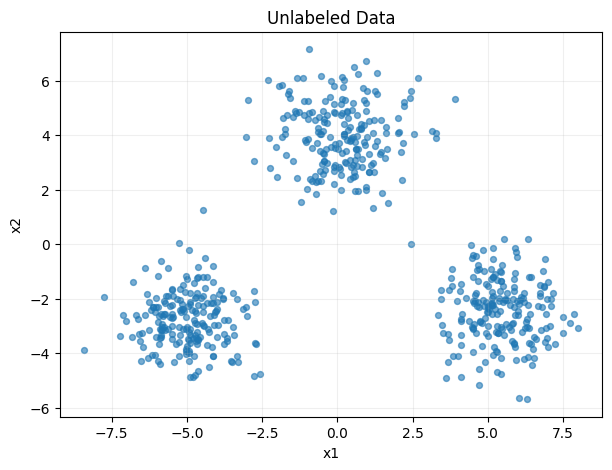

In [3]:
# Label이 없으므로 모든 Sample을 같은 색으로 표시한다.
plt.figure(figsize=(7, 5))
plt.scatter(X['x1'], X['x2'], s=18, alpha=0.6)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Unlabeled Data')
plt.grid(alpha=0.2)
plt.show()

## Centroid and Distance

K-Means는 먼저 Cluster의 개수 `k`를 정한 다음, 각 Cluster를 대표하는 중심점인 Centroid를 찾는다.

두 Sample $X=(x_1,x_2)$와 $C=(c_1,c_2)$ 사이의 Euclidean Distance는 다음과 같다.

$$
d(X,C)=\sqrt{(x_1-c_1)^2+(x_2-c_2)^2}
$$

하나의 Sample은 가장 가까운 Centroid에 할당된다.

$$
\text{Cluster}(X)=\arg\min_{j\in\{1,\ldots,k\}} d(X,C_j)
$$

Centroid는 해당 Cluster에 속한 Samples의 Feature별 평균이다. 따라서 Centroid가 반드시 실제 관측 Sample일 필요는 없다.

## K-Means Step by Step

K-Means는 아래 두 작업을 반복한다.

- Assignment: 각 Sample을 가장 가까운 Centroid에 할당
- Update: 각 Cluster에 속한 Samples의 평균으로 Centroid를 이동

Centroid의 위치 또는 Sample Assignment가 더 이상 실질적으로 변하지 않으면 반복을 종료한다.

먼저 Sample이 6개뿐인 작은 예제로 이 과정을 직접 계산한다.

In [13]:
# 작고 단순한 Data로 K-Means의 첫 번째 Assignment를 확인한다.
toy = pd.DataFrame({
    'x1': [1.0, 1.5, 2.0, 8.0, 8.0, 9.0],
    'x2': [1.0, 2.0, 1.0, 8.0, 9.0, 8.0]
})

initial_centers = np.array([[2.0, 5.0], [8.0, 5.0]])

# Shape: (6 samples, 2 centroids, 2 features)
distance = np.linalg.norm(
    toy.to_numpy()[:, None, :] - initial_centers[None, :, :],
    axis=2
)

assignment = np.argmin(distance, axis=1)

toy_result = toy.copy()
toy_result['Distance to C0'] = distance[:, 0].round(3)
toy_result['Distance to C1'] = distance[:, 1].round(3)
toy_result['Assigned Cluster'] = assignment

display(toy_result)

,x1,x2,Distance to C0,Distance to C1,Assigned Cluster
0,1.0,1.0,4.123,8.062,0
1,1.5,2.0,3.041,7.159,0
2,2.0,1.0,4.000,7.211,0
3,8.0,8.0,6.708,3.000,1
4,8.0,9.0,7.211,4.000,1
5,9.0,8.0,7.616,3.162,1


Initial Centers:
[[2. 5.]
 [8. 5.]]

Updated Centers:
[[1.5        1.33333333]
 [8.33333333 8.33333333]]

Assignment after Update: [0 0 0 1 1 1]
Assignment Changed: False


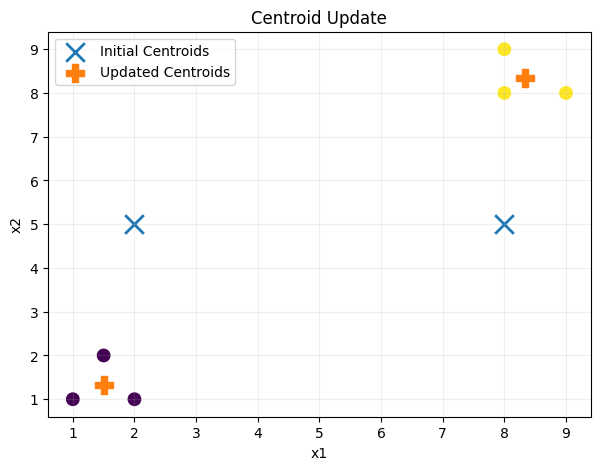

In [14]:
# 각 Cluster에 속하는 Samples의 Mean으로 Centroid를 갱신한다.
updated_centers = np.vstack([
    toy.to_numpy()[assignment == j].mean(axis=0)
    for j in range(2)
])

print('Initial Centers:')
print(initial_centers)
print('\nUpdated Centers:')
print(updated_centers)

# Update 이후 가장 가까운 Centroid를 다시 찾는다.
new_distance = np.linalg.norm(
    toy.to_numpy()[:, None, :] - updated_centers[None, :, :],
    axis=2
)
new_assignment = np.argmin(new_distance, axis=1)
print('\nAssignment after Update:', new_assignment)
print('Assignment Changed:', not np.array_equal(assignment, new_assignment))

plt.figure(figsize=(7, 5))
plt.scatter(toy['x1'], toy['x2'], c=assignment, s=80, cmap='viridis')
plt.scatter(initial_centers[:, 0], initial_centers[:, 1],
            marker='x', s=180, linewidths=2, label='Initial Centroids')
plt.scatter(updated_centers[:, 0], updated_centers[:, 1],
            marker='P', s=170, label='Updated Centroids')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Centroid Update')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## K-Means with scikit-learn

이제 실제 CSV Data에 K-Means를 적용한다.

`KMeans(n_clusters=3)`은 세 개의 Cluster를 찾도록 지시하는 것이다. K-Means가 스스로 `k=3`을 정하는 것은 아니다.

- `n_clusters`: Cluster 개수 $k$
- `random_state`: Random Initialization의 재현성
- `n_init`: 초기 Centroid를 달리하여 학습하는 횟수

`fit_predict(X)`는 Centroids를 학습하고 각 Sample의 Cluster Label을 반환한다.

In [15]:
# 정답 y 없이 X만 사용한다.
model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(X)

print('Number of Clusters:', model.n_clusters)
print('Centroids:')
print(model.cluster_centers_)
print('Cluster Labels (first 20):', labels[:20])
print('Iterations:', model.n_iter_)
print('Inertia:', round(model.inertia_, 2))

Number of Clusters: 3
Centroids:
[[ 5.4194044  -2.4313315 ]
 [-4.99334066 -2.75930723]
 [ 0.12708835  3.98088561]]
Cluster Labels (first 20): [1 0 1 0 2 1 2 0 0 0 2 1 0 0 1 2 1 1 1 1]
Iterations: 2
Inertia: 1460.98


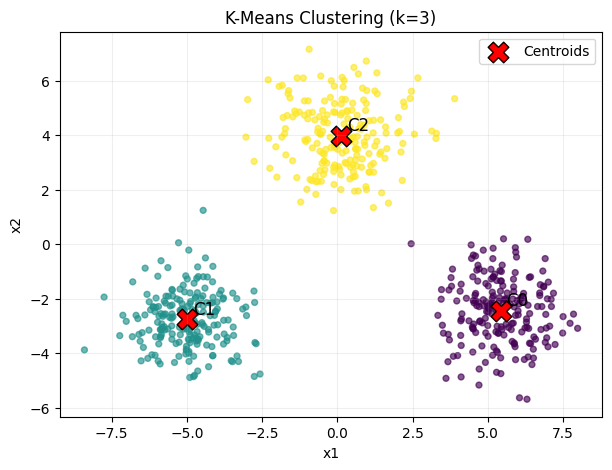

In [16]:
# Cluster Label로 색을 구별하고 Centroid를 표시한다.
plt.figure(figsize=(7, 5))
plt.scatter(X['x1'], X['x2'], c=labels,
            cmap='viridis', s=18, alpha=0.65)
plt.scatter(model.cluster_centers_[:, 0],
            model.cluster_centers_[:, 1],
            c='red', marker='X', s=220,
            edgecolors='black', label='Centroids')

for j, (cx, cy) in enumerate(model.cluster_centers_):
    plt.text(cx + 0.2, cy + 0.2, f'C{j}', fontsize=12)

plt.xlabel('x1')
plt.ylabel('x2')
plt.title('K-Means Clustering (k=3)')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Interpreting the Clustering Result

K-Means의 결과에서 확인할 수 있는 내용은 다음과 같다.

- 각 Sample에 할당된 Cluster Label
- 각 Cluster에 속한 Sample 수
- 각 Cluster의 Centroid 위치
- Centroid까지의 Distance가 전체적으로 얼마나 작은지

Cluster 번호 `0`, `1`, `2`는 단순한 식별번호다. 다른 실행에서는 번호가 바뀔 수 있지만 Clustering 자체는 동일할 수 있다.

새로운 Sample이 들어오면 학습된 Centroids 중 가장 가까운 곳에 할당할 수도 있다.

In [17]:
# Cluster별 Sample 수와 Centroid를 해석한다.
cluster_counts = pd.Series(labels).value_counts().sort_index()
centroid_table = pd.DataFrame(
    model.cluster_centers_, columns=['Centroid x1', 'Centroid x2']
)
centroid_table['Samples'] = cluster_counts.to_numpy()
centroid_table.index.name = 'Cluster'

display(centroid_table.round(3))

# 이미 학습한 Centroids를 이용해 새로운 Sample을 할당한다.
new_samples = pd.DataFrame({'x1': [-5.0, 0.0, 5.0],
                            'x2': [-3.0, 4.0, -2.0]})
print('New Sample Predictions:', model.predict(new_samples))

,Centroid x1,Centroid x2,Samples
Cluster,,,
0,5.419,-2.431,200
1,-4.993,-2.759,200
2,0.127,3.981,200


New Sample Predictions: [1 2 0]


## What Happens If We Change k?

`k`는 K-Means를 실행하기 전에 사용자가 선택한다.

- 너무 작은 `k`: 서로 다른 Group이 하나의 Cluster로 합쳐질 수 있다.
- 너무 큰 `k`: 하나의 Group이 여러 Cluster로 나뉠 수 있다.

같은 Data를 사용해 `k=2, 3, 4, 5`의 결과를 비교한다.

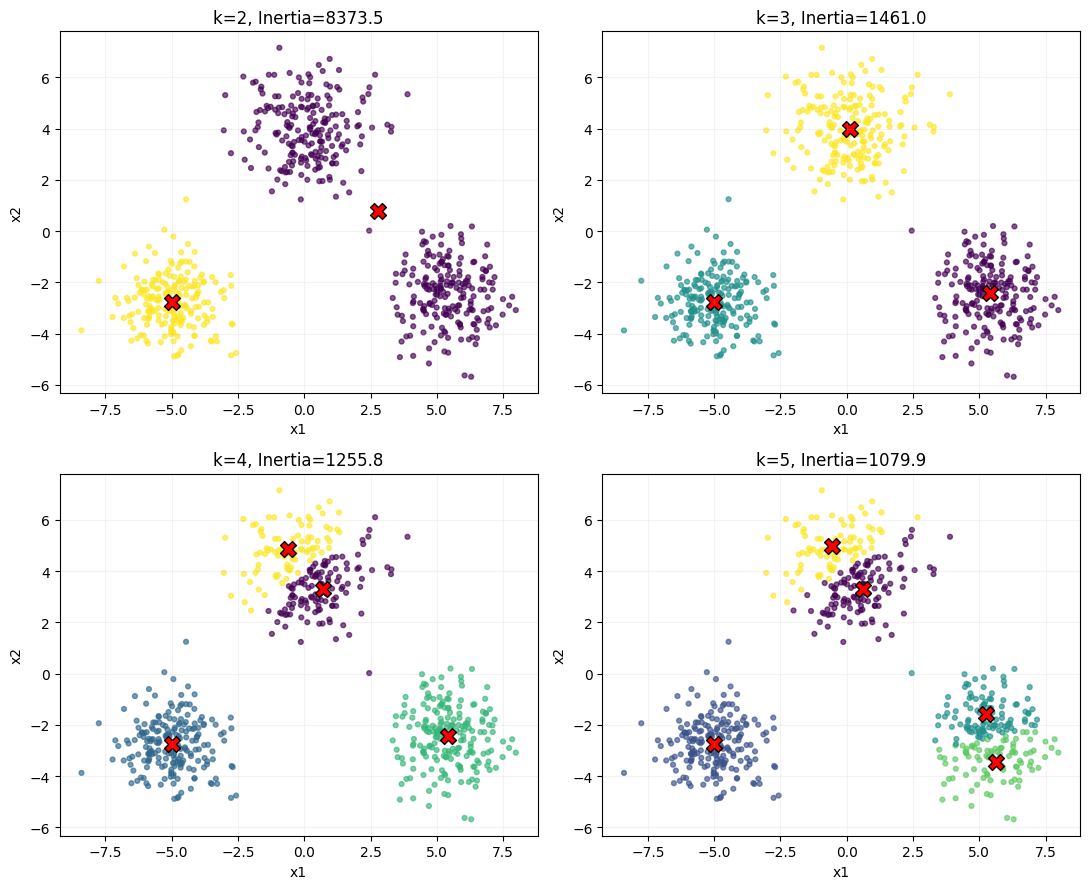

In [18]:
# k 값에 따라 Data가 어떻게 나누어지는지 관찰한다.
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, k in zip(axes.ravel(), [2, 3, 4, 5]):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    assigned = km.fit_predict(X)
    ax.scatter(X['x1'], X['x2'], c=assigned,
               cmap='viridis', s=12, alpha=0.65)
    ax.scatter(km.cluster_centers_[:, 0],
               km.cluster_centers_[:, 1],
               c='red', marker='X', s=130, edgecolors='black')
    ax.set_title(f'k={k}, Inertia={km.inertia_:.1f}')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

## Inertia — How Compact Are the Clusters?

K-Means는 각 Sample과 소속 Centroid 사이의 Squared Distance의 합을 작게 만드는 방향으로 학습한다.

$$
J = \sum_{i=1}^{N}\left\|X_i-C_{a_i}\right\|^2
$$

- $X_i$: Sample $i$
- $C_{a_i}$: Sample $i$가 속한 Cluster의 Centroid
- $J$: Inertia (Within-Cluster Sum of Squares)

Inertia가 작을수록 Sample들이 각 Centroid에 가깝다는 뜻이다.

이론적으로 최적 Inertia는 `k`가 커져도 증가하지 않는다. 따라서 Inertia가 가장 작은 `k`를 무조건 고르면 안 된다.

In [19]:
# sklearn의 Inertia를 직접 계산한 값과 비교한다.
centers_for_samples = model.cluster_centers_[labels]
manual_inertia = np.sum(
    (X.to_numpy() - centers_for_samples) ** 2
)

print('KMeans Inertia:', model.inertia_)
print('Manual Inertia:', manual_inertia)
print('Difference:', abs(model.inertia_ - manual_inertia))

KMeans Inertia: 1460.975639691896
Manual Inertia: 1460.9756396918958
Difference: 2.2737367544323206e-13


## Elbow Method — Choosing k

적절한 `k`를 선택하기 위해 여러 `k`에서 Inertia를 계산한다.

`k`를 늘릴수록 Inertia는 줄어드는 경향이 있다. Elbow Method는 Inertia의 감소 폭이 눈에 띄게 작아지는 지점을 찾는 경험적 방법이다.

Elbow가 뚜렷하지 않은 Data도 있다. 이 방법만으로 항상 하나의 최적 `k`가 결정되는 것은 아니다.

,k,Inertia
0,1,18081.44
1,2,8373.49
2,3,1460.98
3,4,1255.83
4,5,1079.92
5,6,947.05
6,7,815.36
7,8,718.40
8,9,626.18
9,10,574.16


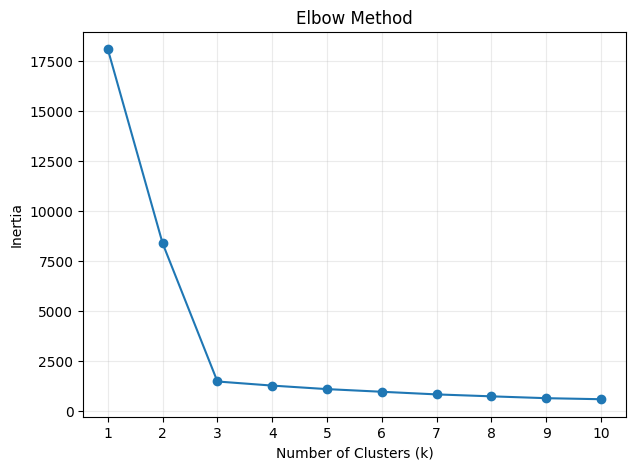

In [20]:
# k=1부터 k=10까지 Inertia를 계산한다.
ks = list(range(1, 11))
inertias = []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertias.append(km.inertia_)

inertia_df = pd.DataFrame({
    'k': ks,
    'Inertia': np.round(inertias, 2)
})
display(inertia_df)

plt.figure(figsize=(7, 5))
plt.plot(ks, inertias, marker='o')
plt.xticks(ks)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid(alpha=0.25)
plt.show()

## Why Does Feature Scaling Matter?

K-Means는 Distance를 이용한다. 따라서 Feature 간 Scale이 크게 다르면 큰 Scale을 가진 Feature가 Distance 계산에 더 큰 영향을 줄 수 있다.

21–22강 SVM에서 다룬 `StandardScaler`를 K-Means에도 적용할 수 있다.

아래 실험에서는 동일한 Data의 `x2`에 100을 곱해 단위만 인위적으로 변경한다. 이렇게 해도 Sample의 원래 정보는 바뀌지 않는다.

Scaling 전후의 Clustering을 비교해 보자.

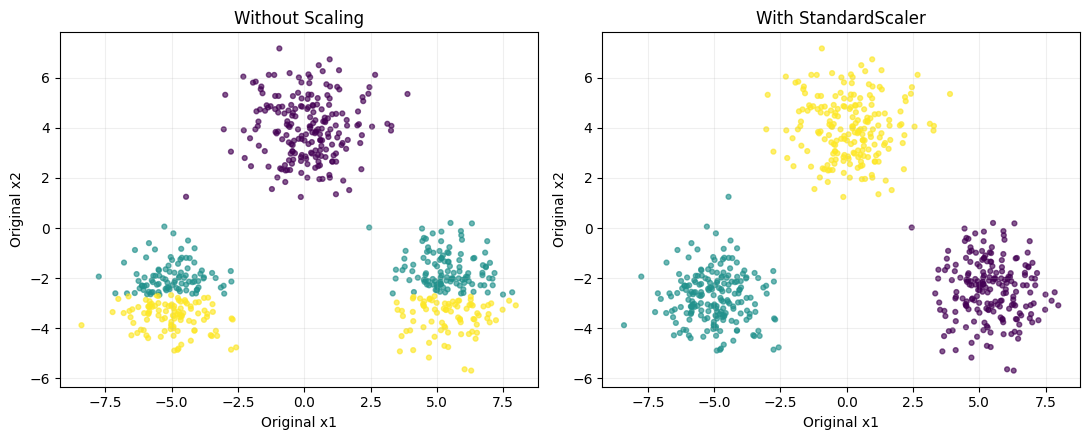

In [21]:
# x2의 단위만 100배로 바꾼다.
X_distorted = X.copy()
X_distorted['x2'] = X_distorted['x2'] * 100

# Scale이 다른 Data에 K-Means를 바로 적용한다.
km_without_scaling = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_without = km_without_scaling.fit_predict(X_distorted)

# StandardScaler를 적용한 후 같은 k로 학습한다.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_distorted)
km_with_scaling = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_with = km_with_scaling.fit_predict(X_scaled)

# 원래 Data의 좌표에서 두 Label 결과를 비교한다.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, label, title in [
    (axes[0], labels_without, 'Without Scaling'),
    (axes[1], labels_with, 'With StandardScaler')
]:
    ax.scatter(X['x1'], X['x2'], c=label,
               cmap='viridis', s=12, alpha=0.65)
    ax.set_title(title)
    ax.set_xlabel('Original x1')
    ax.set_ylabel('Original x2')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## A Limitation of K-Means

K-Means는 Distance와 Centroid를 기반으로 Cluster를 만든다. 따라서 둥글거나 잘 분리된 Group에서는 직관적인 결과를 얻기 쉽다.

하지만 길게 휘어져 있거나 서로 얽힌 Group을 구별하는 데는 적합하지 않을 수 있다.

두 개의 초승달 모양 Group을 예로 살펴보자. 실제 Class Label을 학습에 사용하지 않고 `X`만으로 K-Means를 적용한다.

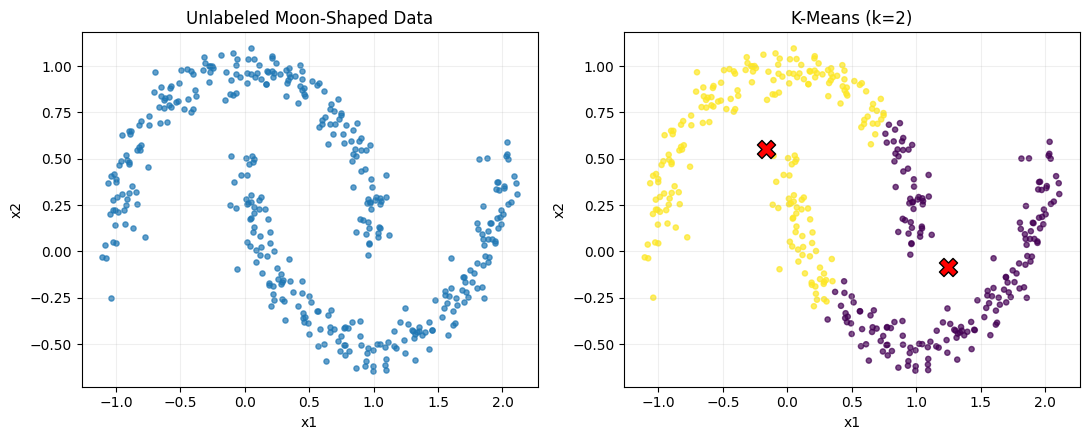

In [22]:
# 초승달 모양 Data에서 K-Means의 한계를 관찰한다.
moon_X, _ = make_moons(
    n_samples=400, noise=0.07, random_state=42
)
moon_model = KMeans(n_clusters=2, random_state=42, n_init=10)
moon_labels = moon_model.fit_predict(moon_X)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(moon_X[:, 0], moon_X[:, 1], s=14, alpha=0.7)
axes[0].set_title('Unlabeled Moon-Shaped Data')

axes[1].scatter(moon_X[:, 0], moon_X[:, 1],
                c=moon_labels, cmap='viridis', s=14, alpha=0.7)
axes[1].scatter(moon_model.cluster_centers_[:, 0],
                moon_model.cluster_centers_[:, 1],
                marker='X', c='red', s=170, edgecolors='black')
axes[1].set_title('K-Means (k=2)')

for ax in axes:
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Summary

- Clustering은 정답 Label 없이 $X$만으로 Group을 찾는 Unsupervised Learning이다.
- K-Means는 Sample을 가장 가까운 Centroid에 Assignment하고 Centroid를 Update한다.
- `k`는 사용자가 정하는 Hyperparameter이며, Inertia와 Elbow Method는 `k`를 선택하는 데 도움을 준다.
- Cluster Label 숫자는 정답 Class를 의미하지 않는다.
- Distance를 사용하므로 Feature Scaling이 중요할 수 있다.
- 복잡하게 굽은 형태의 Group에는 한계가 있다.

다음 강의에서는 Centroid 대신 Data의 밀집영역을 이용하는 DBSCAN을 살펴본다.

## Homework - Problem 23

`kmeans_data2.csv`를 이용하여 K-Means Clustering을 수행하시오.

다음 조건을 사용한다.

- Feature: `x1`, `x2`
- `random_state=42`
- `n_init=10`
- `k=2, 3, 4, 5, 6`

다음 질문에 답하시오.

- 각 `k`에 대한 Inertia를 소수점 둘째 자리까지 적으시오.
- Elbow Method를 이용해 적절한 `k`를 하나 선택하시오.
- 선택한 `k`에서 각 Cluster에 속한 Sample 수를 적으시오. Cluster 번호와 Sample 수를 함께 표시하시오.

강의에서 사용한 Code의 Data File과 `k`만 변경하여 실행할 수 있다.

답만 제출하시오.